# LaptopPrice — Analisis Prediksi Harga Laptop dengan Regresi Linear Berganda

Notebook ini adalah **bahan laporan dan presentasi**. Isinya menelusuri seluruh pipeline langkah demi langkah:

1. Memahami dataset dan formatnya
2. Membersihkan data dan membuat fitur (*feature engineering*)
3. Eksplorasi data (EDA)
4. Membagi data latih/uji dan *preprocessing* tanpa *data leakage*
5. Regresi linear berganda **manual** (Normal Equation & Gradient Descent) dan verifikasinya terhadap scikit-learn
6. Membandingkan semua model dengan baseline memakai 5-Fold Cross Validation
7. Memilih model aktif (aturan 1-SE)
8. Diagnostik residual, learning curve, analisis error, interpretasi koefisien, multikolinearitas
9. Contoh prediksi dan penyesuaian harga ke kondisi sekarang

> Notebook ini **tidak menulis kode ML baru**. Semua fungsi dipanggil dari paket `ml/` (yang juga dipakai API dan website), sehingga angka di sini sama persis dengan yang tampil di website. Notebook juga **tidak menulis ke database**.

Jalankan dari folder `backend` dengan virtualenv aktif: `jupyter notebook analysis.ipynb`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from ml import evaluation as ev
from ml.config import ambil_pengaturan, info_penyesuaian_harga, RANDOM_STATE, Z_95
from ml.model import (RegresiLinearNormalEquation, RegresiLinearGradientDescent,
                      RegresiRidgeManual, buat_model)
from ml.preprocessing import (muat_dataset, bersihkan_data, ekstrak_fitur, target_log, Preprocessor,
                              parse_memori, parse_resolusi, kategori_cpu, hitung_ppi,
                              FITUR_NUMERIK, FITUR_NUMERIK_SEMUA)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110
print("random_state =", RANDOM_STATE)

random_state = 42


## 1. Memahami dataset

Dataset: Kaggle *Laptop Price*. File yang dipakai sudah setengah bersih: kolom RAM, berat, dan frekuensi CPU sudah berupa angka, dan CPU sudah dipecah menjadi tiga kolom. `muat_dataset()` membaca CSV dan menyeragamkan nama kolom (mis. `Price (Euro)` → `Price_euros`).

In [2]:
df_mentah = muat_dataset(ambil_pengaturan().path_dataset)
print("Ukuran:", df_mentah.shape)
print("Nilai kosong total:", int(df_mentah.isna().sum().sum()))
print("Baris duplikat penuh:", int(df_mentah.duplicated().sum()))
display(df_mentah.head())

Ukuran: (1275, 15)
Nilai kosong total: 0
Baris duplikat penuh: 0


,Company,Product,TypeName,Inches,ScreenResolution,CPU_Company,CPU_Type,CPU_GHz,Ram,Memory,GPU_Company,GPU_Type,OpSys,Weight,Price_euros
0,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel,Core i5,2.3,8,128GB SSD,Intel,Iris Plus Graphics 640,macOS,1.37,1339.69
1,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel,Core i5,1.8,8,128GB Flash Storage,Intel,HD Graphics 6000,macOS,1.34,898.94
2,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel,Core i5 7200U,2.5,8,256GB SSD,Intel,HD Graphics 620,No OS,1.86,575.00
3,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel,Core i7,2.7,16,512GB SSD,AMD,Radeon Pro 455,macOS,1.83,2537.45
4,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel,Core i5,3.1,8,256GB SSD,Intel,Iris Plus Graphics 650,macOS,1.37,1803.60


Kolom teks yang harus diubah menjadi angka: `ScreenResolution` dan `Memory`. Format yang benar-benar ada di file perlu dilihat dulu, jangan diasumsikan:

In [3]:
print("Contoh format Memory (", df_mentah["Memory"].nunique(), "variasi):")
print(df_mentah["Memory"].value_counts().head(12).to_string())
print("\nContoh format ScreenResolution:")
print(df_mentah["ScreenResolution"].value_counts().head(8).to_string())
print("\nCPU_Company:", df_mentah["CPU_Company"].value_counts().to_dict())
print("GPU_Company:", df_mentah["GPU_Company"].value_counts().to_dict())

Contoh format Memory ( 39 variasi):
Memory
256GB SSD               412
1TB HDD                 215
500GB HDD               124
512GB SSD               114
128GB SSD +  1TB HDD     94
128GB SSD                74
256GB SSD +  1TB HDD     73
32GB Flash Storage       36
2TB HDD                  16
512GB SSD +  1TB HDD     14
1TB SSD                  14
64GB Flash Storage       13

Contoh format ScreenResolution:
ScreenResolution
Full HD 1920x1080                            505
1366x768                                     263
IPS Panel Full HD 1920x1080                  226
IPS Panel Full HD / Touchscreen 1920x1080     51
Full HD / Touchscreen 1920x1080               47
1600x900                                      23
Touchscreen 1366x768                          16
Quad HD+ / Touchscreen 3200x1800              15

CPU_Company: {'Intel': 1214, 'AMD': 60, 'Samsung': 1}
GPU_Company: {'Intel': 704, 'Nvidia': 396, 'AMD': 174, 'ARM': 1}


## 2. Pembersihan & feature engineering

**Pembersihan.** Ada satu laptop dengan prosesor ARM (Samsung Chromebook Plus). Satu data tidak cukup untuk mempelajari efek kategorinya, dan kolom one-hot CPU=Lainnya serta GPU=Lainnya akan identik (kolinearitas sempurna), sehingga baris ini dikeluarkan.

**Feature engineering** (fungsi di `ml/preprocessing.py`):
- `parse_resolusi()`: lebar, tinggi, flag Touchscreen dan IPS dari teks resolusi
- `hitung_ppi()`: kerapatan piksel = diagonal piksel ÷ diagonal inci
- `parse_memori()`: kapasitas SSD, HDD, dan Flash dalam GB (1 TB = 1000 GB, Hybrid dihitung HDD)
- `kategori_cpu()`: Intel Core i3/i5/i7, Intel Lainnya, AMD
- RAM dan kapasitas penyimpanan juga dibuat versi log2 (lihat bagian 7)

In [4]:
print(parse_memori("128GB SSD +  1TB HDD"))
print(parse_memori("1.0TB Hybrid"))
print(parse_resolusi("IPS Panel Full HD / Touchscreen 1920x1080"))
print("PPI 1920x1080 @ 15.6 inci =", round(hitung_ppi(1920, 1080, 15.6), 1))
print(kategori_cpu("Intel", "Core i5 7200U"), "|", kategori_cpu("Intel", "Celeron Dual Core N3350"), "|", kategori_cpu("AMD", "Ryzen 1700"))

{'SSD_GB': 128.0, 'HDD_GB': 1000.0, 'Flash_GB': 0.0}
{'SSD_GB': 0.0, 'HDD_GB': 1000.0, 'Flash_GB': 0.0}
{'Lebar_px': 1920, 'Tinggi_px': 1080, 'Touchscreen': 1, 'IPS': 1}
PPI 1920x1080 @ 15.6 inci = 141.2
Intel Core i5 | Intel Lainnya | AMD


In [5]:
df, dibuang = bersihkan_data(df_mentah)
print("Baris dibuang:", dibuang)
F = ekstrak_fitur(df)        # tabel fitur (per baris, belum ada yang "dipelajari")
y = target_log(df)           # target = ln(harga)
print("Jumlah data dipakai:", len(df))
display(F.head())

Baris dibuang: [{'indeks': 1191, 'company': 'Samsung', 'product': 'Chromebook Plus', 'alasan': 'CPU Samsung Cortex A72&A53 (bukan Intel/AMD)'}]
Jumlah data dipakai: 1274


,Company,TypeName,Inches,Ram,Weight,CPU_GHz,Lebar_px,Tinggi_px,Touchscreen,IPS,SSD_GB,HDD_GB,Flash_GB,CPU_Kategori,GPU_Merek,OS,PPI,Ram_log2,SSD_log2,HDD_log2,Flash_log2
0,Apple,Ultrabook,13.3,8.0,1.37,2.3,2560,1600,0,1,128.0,0.0,0.0,Intel Core i5,Intel,macOS,226.983005,3.0,7.011227,0.0,0.000000
1,Apple,Ultrabook,13.3,8.0,1.34,1.8,1440,900,0,0,0.0,0.0,128.0,Intel Core i5,Intel,macOS,127.677940,3.0,0.000000,0.0,7.011227
2,HP,Notebook,15.6,8.0,1.86,2.5,1920,1080,0,0,256.0,0.0,0.0,Intel Core i5,Intel,Tanpa OS,141.211998,3.0,8.005625,0.0,0.000000
3,Apple,Ultrabook,15.4,16.0,1.83,2.7,2880,1800,0,1,512.0,0.0,0.0,Intel Core i7,AMD,macOS,220.534624,4.0,9.002815,0.0,0.000000
4,Apple,Ultrabook,13.3,8.0,1.37,3.1,2560,1600,0,1,256.0,0.0,0.0,Intel Core i5,Intel,macOS,226.983005,3.0,8.005625,0.0,0.000000


## 3. Eksplorasi data

### 3.1 Mengapa target memakai ln(harga)?
Harga laptop miring ke kanan. Setelah diambil logaritmanya, distribusinya hampir simetris. Selain itu, pengaruh spesifikasi terhadap harga bersifat persentase (perkalian), yang menjadi penjumlahan di skala log, sehingga cocok untuk model linear.

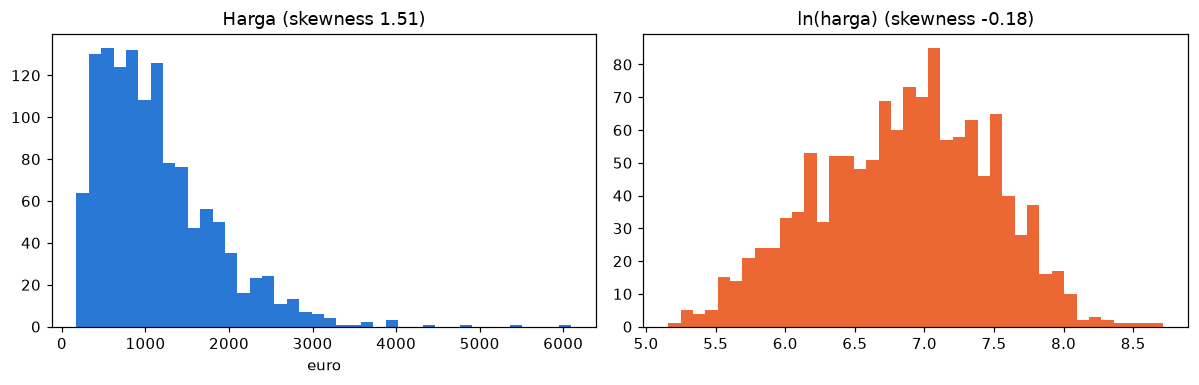

In [6]:
harga = df["Price_euros"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(harga, bins=40, color="#2a78d6"); ax[0].set_title(f"Harga (skewness {harga.skew():.2f})"); ax[0].set_xlabel("euro")
ax[1].hist(np.log(harga), bins=40, color="#eb6834"); ax[1].set_title(f"ln(harga) (skewness {np.log(harga).skew():.2f})")
plt.tight_layout(); plt.show()

### 3.2 Korelasi fitur numerik
Perhatikan bahwa lebar, tinggi resolusi, dan PPI saling berkorelasi sangat tinggi. Ini tanda awal multikolinearitas yang dibahas di bagian 9.

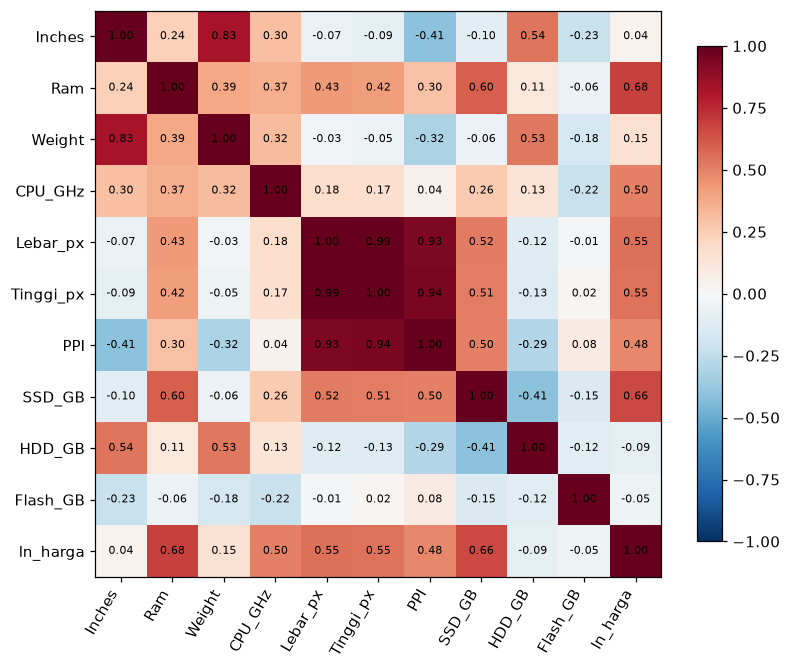

Ram          0.681
SSD_GB       0.659
Lebar_px     0.547
Tinggi_px    0.545
CPU_GHz      0.501
PPI          0.481
Weight       0.151
Inches       0.038
Flash_GB    -0.051
HDD_GB      -0.094


In [7]:
kolom = ["Inches", "Ram", "Weight", "CPU_GHz", "Lebar_px", "Tinggi_px", "PPI", "SSD_GB", "HDD_GB", "Flash_GB"]
korelasi = F[kolom].assign(ln_harga=y).corr()
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(korelasi, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(korelasi)), korelasi.columns, rotation=60, ha="right"); ax.set_yticks(range(len(korelasi)), korelasi.columns)
for i in range(len(korelasi)):
    for j in range(len(korelasi)):
        ax.text(j, i, f"{korelasi.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, shrink=0.8); plt.tight_layout(); plt.show()
print(korelasi["ln_harga"].drop("ln_harga").sort_values(ascending=False).round(3).to_string())

In [8]:
ringkas = (df.assign(Tipe=F["TypeName"]).groupby("Tipe")["Price_euros"]
             .agg(jumlah="size", median="median", rata_rata="mean").sort_values("median", ascending=False))
display(ringkas.round(0))

,jumlah,median,rata_rata
Tipe,,,
Workstation,29,2065.0,2280.0
Ultrabook,194,1499.0,1557.0
Gaming,205,1493.0,1731.0
2 in 1 Convertible,116,1239.0,1295.0
Notebook,707,695.0,789.0
Netbook,23,355.0,673.0


## 4. Split latih/uji & preprocessing tanpa data leakage

- Data dibagi **80% latih / 20% uji** dengan `random_state` tetap. Data uji tidak disentuh sampai evaluasi akhir.
- `Preprocessor.fit()` hanya dipanggil pada data latih: rata-rata & std untuk standardisasi, daftar kategori, dan kategori acuan one-hot dipelajari dari data latih saja.
- One-hot memakai **drop-first** (kategori acuan = yang paling sering muncul) untuk menghindari *dummy variable trap*.
- Kolom one-hot yang isinya identik dengan kolom lain dibuang otomatis.

In [9]:
idx_latih, idx_uji = ev.bagi_latih_uji(len(df))
F_latih, F_uji = F.iloc[idx_latih].reset_index(drop=True), F.iloc[idx_uji].reset_index(drop=True)
y_latih, y_uji = y[idx_latih], y[idx_uji]
print("latih:", len(idx_latih), "| uji:", len(idx_uji))

pp = Preprocessor().fit(F_latih)
X_latih, X_uji = pp.transform(F_latih), pp.transform(F_uji)
print("Ukuran X latih:", X_latih.shape)
print("Kategori acuan:", pp.kategori_acuan_)
print("Kolom identik yang dibuang:", pp.kolom_duplikat_)
Z = X_latih[:, :len(FITUR_NUMERIK)]
print("Rata-rata kolom numerik terstandar (harus ~0):", np.round(Z.mean(axis=0), 10))
print("Std kolom numerik terstandar (harus 1):", np.round(Z.std(axis=0), 10))

latih: 1019 | uji: 255
Ukuran X latih: (1019, 34)
Kategori acuan: {'Company': 'Dell', 'TypeName': 'Notebook', 'CPU_Kategori': 'Intel Core i7', 'GPU_Merek': 'Intel', 'OS': 'Windows'}
Kolom identik yang dibuang: [{'dibuang': 'OS=macOS', 'identik_dengan': 'Company=Apple'}]
Rata-rata kolom numerik terstandar (harus ~0): [ 0. -0. -0.  0. -0. -0.  0.  0.]
Std kolom numerik terstandar (harus 1): [1. 1. 1. 1. 1. 1. 1. 1.]


## 5. Regresi linear berganda manual & verifikasi

### 5.1 Normal Equation
$$\mathbf{w} = (X^\top X)^{+} X^\top \mathbf{y}$$
(pseudo-inverse agar tetap aman jika matriks singular)

In [10]:
from sklearn.linear_model import LinearRegression, Ridge
ne = RegresiLinearNormalEquation().fit(X_latih, y_latih)
sk = LinearRegression().fit(X_latih, y_latih)
print("Intersep manual vs sklearn:", ne.intercept_, sk.intercept_)
print("Selisih maksimum koefisien manual vs sklearn:", np.max(np.abs(ne.coef_ - sk.coef_)))
print("Selisih maksimum prediksi uji:", np.max(np.abs(ne.predict(X_uji) - sk.predict(X_uji))))

Intersep manual vs sklearn: 6.902150893923434 6.902150893923409
Selisih maksimum koefisien manual vs sklearn: 1.7993939671612225e-13
Selisih maksimum prediksi uji: 1.8207657603852567e-13


### 5.2 Gradient Descent
$$\mathbf{w} \leftarrow \mathbf{w} - \eta\,\tfrac{2}{n}X^\top(X\mathbf{w}-\mathbf{y})$$
Langkah stabil jika $\eta < 2/\lambda_{\max}$, dengan $\lambda_{\max}$ nilai eigen terbesar dari $\tfrac{2}{n}X^\top X$.

lambda_maks = 6.203  ->  learning rate maksimum stabil = 0.322


Iterasi dijalankan: 9123
Selisih maksimum koefisien GD vs Normal Equation: 2.5742080304633208e-05


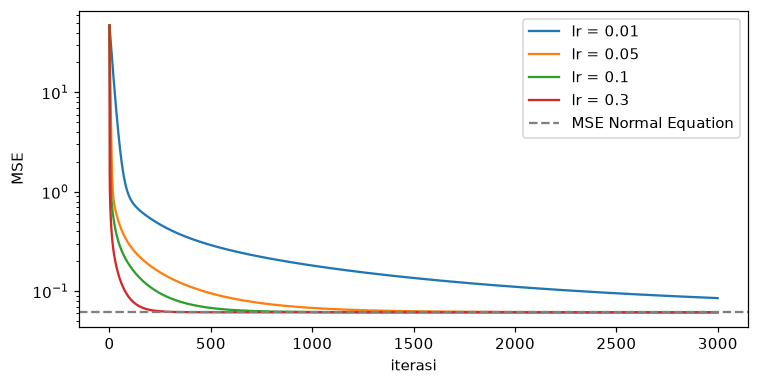

In [11]:
Xb = np.hstack([np.ones((len(X_latih), 1)), X_latih])
lam_maks = np.linalg.eigvalsh((2 / len(X_latih)) * Xb.T @ Xb).max()
print(f"lambda_maks = {lam_maks:.3f}  ->  learning rate maksimum stabil = {2 / lam_maks:.3f}")

gd = RegresiLinearGradientDescent(learning_rate=0.1, n_iterasi=20000, toleransi=1e-14).fit(X_latih, y_latih)
print("Iterasi dijalankan:", gd.n_iterasi_dijalankan_)
print("Selisih maksimum koefisien GD vs Normal Equation:", np.max(np.abs(gd.coef_ - ne.coef_)))

fig, ax = plt.subplots(figsize=(7, 3.6))
for lr in [0.01, 0.05, 0.1, 0.3]:
    m = RegresiLinearGradientDescent(learning_rate=lr, n_iterasi=3000, toleransi=None).fit(X_latih, y_latih)
    ax.plot(m.riwayat_loss_, label=f"lr = {lr}")
ax.axhline(np.mean((ne.predict(X_latih) - y_latih) ** 2), color="gray", ls="--", label="MSE Normal Equation")
ax.set_yscale("log"); ax.set_xlabel("iterasi"); ax.set_ylabel("MSE"); ax.legend(); plt.tight_layout(); plt.show()

### 5.3 Ridge manual vs sklearn, dan metrik manual vs `sklearn.metrics`

In [12]:
for alpha in [0.1, 1, 10]:
    rm = RegresiRidgeManual(alpha).fit(X_latih, y_latih)
    rs = Ridge(alpha=alpha).fit(X_latih, y_latih)
    print(f"alpha={alpha:<4} selisih maks koefisien Ridge manual vs sklearn = {np.max(np.abs(rm.coef_ - rs.coef_)):.2e}")

aktual, prediksi = np.exp(y_uji), np.exp(ne.predict(X_uji))
display(pd.DataFrame(ev.verifikasi_metrik(aktual, prediksi)))

alpha=0.1  selisih maks koefisien Ridge manual vs sklearn = 1.63e-14
alpha=1    selisih maks koefisien Ridge manual vs sklearn = 1.51e-14
alpha=10   selisih maks koefisien Ridge manual vs sklearn = 8.97e-15


,metrik,manual,sklearn,selisih_absolut,sama
0,mae,244.699072,244.699072,0.0,True
1,rmse,433.447424,433.447424,0.0,True
2,mape,19.885422,19.885422,0.0,True
3,r2,0.688136,0.688136,0.0,True


## 6. Semua model vs baseline (5-Fold CV + data uji)

`jalankan_pipeline()` di `ml/train.py` menjalankan seluruh langkah evaluasi: pemilihan alpha Ridge, 5-Fold CV setiap model (preprocessing di-fit ulang di setiap fold), evaluasi data uji, data residual, learning curve, analisis error, verifikasi, dan multikolinearitas. Di notebook ini hasilnya **tidak disimpan ke database**.

In [13]:
from ml.train import jalankan_pipeline
hasil, model_terlatih = jalankan_pipeline(log=lambda *_: None)

baris = []
for nama, m in hasil["model"].items():
    r, u = m["cv"]["ringkasan"], m["metrik"]["uji"]
    baris.append({"model": nama,
                  "RMSE CV": f'{r["rmse"]["rata_rata"]:.1f} ± {r["rmse"]["std"]:.1f}',
                  "MAPE CV %": f'{r["mape"]["rata_rata"]:.2f} ± {r["mape"]["std"]:.2f}',
                  "R2 CV": round(r["r2"]["rata_rata"], 4),
                  "RMSE uji": round(u["rmse"], 1), "MAE uji": round(u["mae"], 1),
                  "MAPE uji %": round(u["mape"], 2), "R2 uji": round(u["r2"], 4), "R2 log uji": round(u["r2_log"], 4)})
perbandingan = pd.DataFrame(baris).set_index("model")
display(perbandingan)

,RMSE CV,MAPE CV %,R2 CV,RMSE uji,MAE uji,MAPE uji %,R2 uji,R2 log uji
model,,,,,,,,
baseline_rata_rata,680.0 ± 43.6,71.45 ± 7.20,-0.0072,777.0,537.6,67.96,-0.0022,-0.0644
ols_normal_equation,359.8 ± 57.1,20.58 ± 1.11,0.7181,433.4,244.7,19.89,0.6881,0.8314
ols_gradient_descent,359.8 ± 57.1,20.58 ± 1.11,0.7181,433.4,244.7,19.89,0.6881,0.8314
ols_sklearn,359.8 ± 57.1,20.58 ± 1.11,0.7181,433.4,244.7,19.89,0.6881,0.8314
ridge_manual,358.7 ± 55.6,20.56 ± 1.06,0.7198,432.3,245.2,19.94,0.6898,0.8315
ridge_sklearn,358.7 ± 55.6,20.56 ± 1.06,0.7198,432.3,245.2,19.94,0.6898,0.8315
polinomial_d2,351.5 ± 61.7,19.21 ± 1.09,0.7311,446.8,229.6,17.73,0.6686,0.8445


## 7. Memilih model aktif: aturan 1-SE

Model dengan RMSE CV terkecil belum tentu paling baik, karena selisih kecil bisa saja hanya kebetulan pembagian fold. Aturan **1-SE**: hitung standard error RMSE model terbaik (std antar-fold ÷ √5), lalu pilih model **paling sederhana** yang RMSE CV-nya masih di bawah batas tersebut. Keputusan ini diambil dari CV, bukan dari data uji.

In [14]:
p = hasil["pemilihan_model"]
print(f'RMSE CV terkecil : {p["model_rmse_terkecil"]} = {p["rmse_terkecil"]:.2f}')
print(f'Standard error   : {p["standard_error"]:.2f}  -> batas 1-SE = {p["batas_1se"]:.2f}')
display(pd.DataFrame(p["kandidat"]))
print("MODEL AKTIF:", p["model_terpilih"])

RMSE CV terkecil : polinomial_d2 = 351.55
Standard error   : 27.60  -> batas 1-SE = 379.14


,model,rmse_cv,kompleksitas,dalam_batas_1se
0,ols_normal_equation,359.780664,1,True
1,ols_gradient_descent,359.780422,1,True
2,ols_sklearn,359.780664,1,True
3,ridge_manual,358.738985,2,True
4,ridge_sklearn,358.738985,2,True
5,polinomial_d2,351.545301,3,True


MODEL AKTIF: ols_normal_equation


### Pengaruh log2(RAM) — keputusan yang diambil dari CV
Versi awal memakai RAM dalam GB secara linear. Analisis error menunjukkan satu laptop RAM 64 GB ditebak jauh terlalu mahal (ekstrapolasi). Perbaikan dengan log2 dibandingkan **hanya dengan CV di data latih**:

In [15]:
def rmse_cv_dengan(ubah):
    G = F_latih.copy(); ubah(G)
    from ml.model import ModelHargaLaptop
    pembuat = lambda: ModelHargaLaptop("x", RegresiLinearNormalEquation(), Preprocessor(fitur_numerik=FITUR_NUMERIK))
    return ev.validasi_silang(pembuat, G, y_latih)["ringkasan"]["rmse"]["rata_rata"]

def ram_linear(G):
    G["Ram_log2"] = G["Ram"]                                   # RAM apa adanya (GB)
    for j in ("SSD", "HDD", "Flash"): G[f"{j}_log2"] = G[f"{j}_GB"]
print(f"RAM & penyimpanan linear (GB) : RMSE CV = {rmse_cv_dengan(ram_linear):.1f}")
print(f"RAM & penyimpanan log2        : RMSE CV = {rmse_cv_dengan(lambda G: None):.1f}")

RAM & penyimpanan linear (GB) : RMSE CV = 389.1


RAM & penyimpanan log2        : RMSE CV = 359.8


## 8. Diagnostik model aktif

### 8.1 Prediksi vs aktual & residual

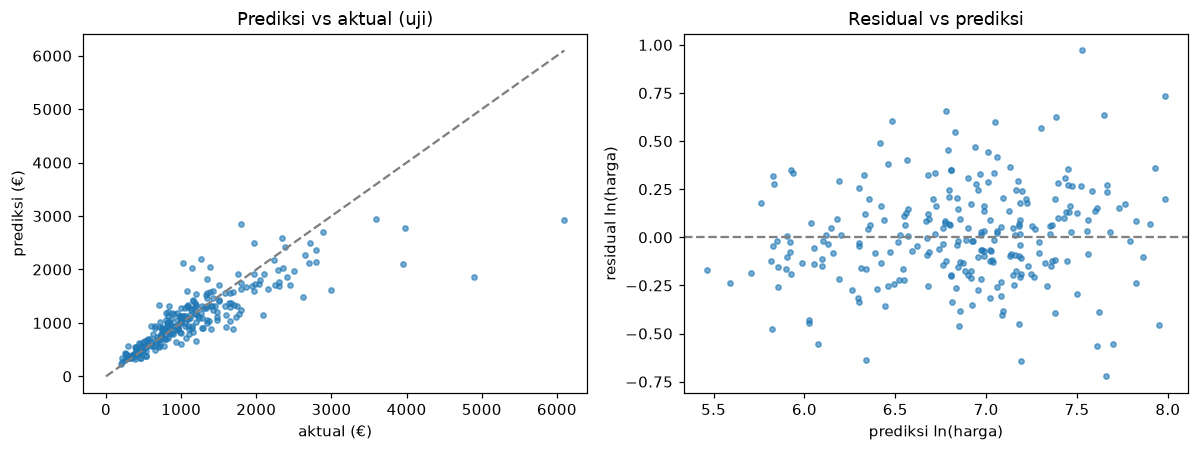

In [16]:
aktif = hasil["model_terbaik"]
m = hasil["model"][aktif]
t = pd.DataFrame(m["residual"]["titik"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].scatter(t.aktual_euro, t.prediksi_euro, s=12, alpha=.6); b = t[["aktual_euro", "prediksi_euro"]].max().max()
ax[0].plot([0, b], [0, b], "--", c="gray"); ax[0].set_xlabel("aktual (€)"); ax[0].set_ylabel("prediksi (€)"); ax[0].set_title("Prediksi vs aktual (uji)")
ax[1].scatter(np.log(t.prediksi_euro), t.residual_log, s=12, alpha=.6); ax[1].axhline(0, c="gray", ls="--")
ax[1].set_xlabel("prediksi ln(harga)"); ax[1].set_ylabel("residual ln(harga)"); ax[1].set_title("Residual vs prediksi")
plt.tight_layout(); plt.show()

### 8.2 Normalitas residual (histogram, Q-Q plot, Shapiro-Wilk)

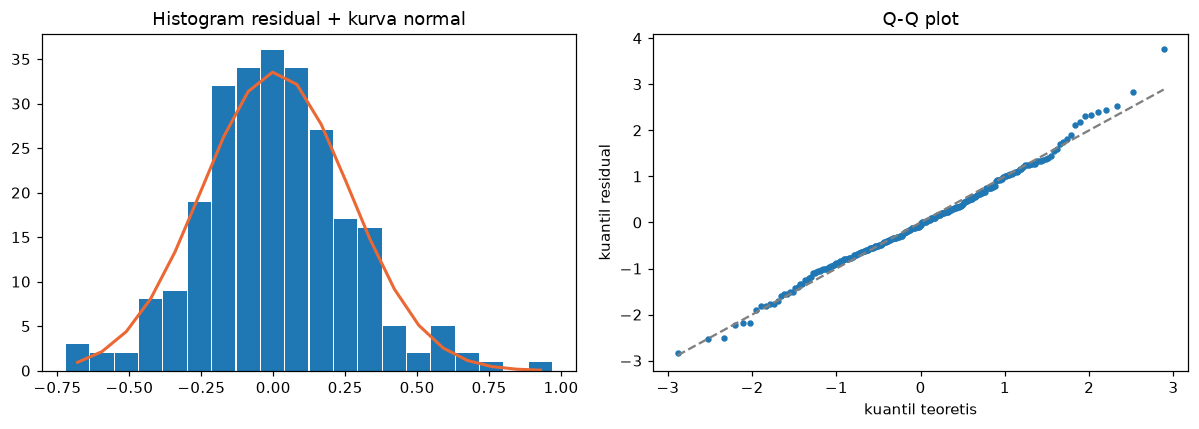

n                                    255.0000
rata_rata_residual_log                 0.0072
std_residual_log                       0.2567
skewness                               0.2651
kurtosis_excess                        0.7574
shapiro_w                              0.9904
shapiro_p                              0.0897
korelasi_abs_residual_vs_prediksi      0.1148
dtype: float64

In [17]:
h = pd.DataFrame(m["residual"]["histogram"]); q = pd.DataFrame(m["qq_plot"]["titik"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(h.tengah, h.frekuensi, width=(h.bin_kanan - h.bin_kiri) * .95); ax[0].plot(h.tengah, h.frekuensi_normal, c="#eb6834", lw=2)
ax[0].set_title("Histogram residual + kurva normal")
ax[1].scatter(q.teoretis, q.sampel, s=10); lim = [q.teoretis.min(), q.teoretis.max()]; ax[1].plot(lim, lim, "--", c="gray")
ax[1].set_title("Q-Q plot"); ax[1].set_xlabel("kuantil teoretis"); ax[1].set_ylabel("kuantil residual")
plt.tight_layout(); plt.show()
display(pd.Series(m["residual"]["statistik"]).round(4))

### 8.3 Apakah rentang perkiraan ±1,96·RMSE benar-benar mencakup ~95%?

In [18]:
display(pd.Series(m["interval"]).round(3))

z                               1.960
rmse_log_cv                     0.261
target_cakupan_persen          95.000
cakupan_uji_persen             94.118
jumlah_di_luar                 15.000
jumlah_uji                    255.000
batas_bawah_relatif_persen    -40.069
batas_atas_relatif_persen      66.859
dtype: float64

### 8.4 Learning curve

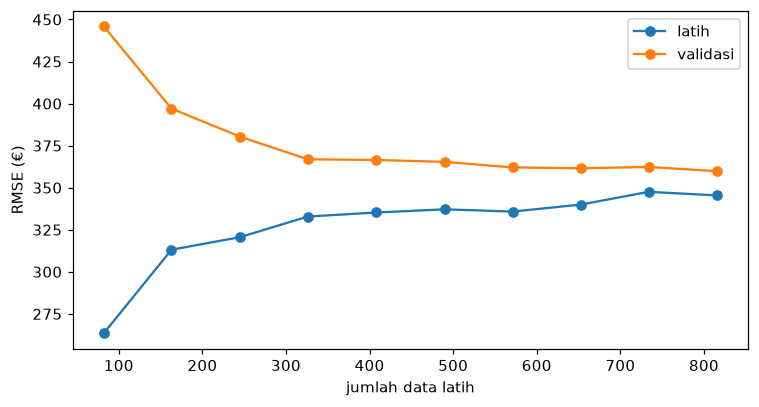

,proporsi,jumlah_data_latih,rmse_latih,rmse_latih_std,rmse_validasi,rmse_validasi_std
0,0.1,82,263.5,41.6,445.9,88.3
1,0.2,163,313.1,24.0,397.0,57.9
2,0.3,245,320.6,30.5,380.3,60.0
3,0.4,326,332.8,24.0,366.9,55.6
4,0.5,408,335.3,12.6,366.5,59.5
5,0.6,490,337.2,9.3,365.3,60.1
6,0.7,571,335.8,14.7,362.1,58.6
7,0.8,653,340.0,13.3,361.5,57.9
8,0.9,734,347.5,14.0,362.4,60.0
9,1.0,816,345.4,11.5,359.8,57.1


In [19]:
lc = pd.DataFrame(m["learning_curve"])
plt.figure(figsize=(7, 3.8))
plt.plot(lc.jumlah_data_latih, lc.rmse_latih, "o-", label="latih"); plt.plot(lc.jumlah_data_latih, lc.rmse_validasi, "o-", label="validasi")
plt.xlabel("jumlah data latih"); plt.ylabel("RMSE (€)"); plt.legend(); plt.tight_layout(); plt.show()
display(lc.round(1))

## 9. Analisis error & interpretasi

### 9.1 Error per tipe dan per merek, serta 10 error terbesar

In [20]:
display(pd.DataFrame(m["error_per_tipe"]).round(1))
display(pd.DataFrame(m["error_per_merek"]).round(1).head(10))
display(pd.DataFrame(m["top_error"])[["company", "product", "typename", "ram", "aktual_euro", "prediksi_euro", "error_persen", "arah"]].round(1))

,grup,n,rata_rata_aktual,rata_rata_prediksi,mae,mape,bias_rata_rata
0,Notebook,148.0,840.0,783.8,165.2,17.7,-56.2
1,Gaming,42.0,1899.3,1639.1,481.2,23.7,-260.2
2,Ultrabook,31.0,1450.2,1519.4,268.6,20.7,69.2
3,2 in 1 Convertible,20.0,1161.7,1236.3,218.9,23.7,74.6
4,Workstation,9.0,2440.1,2207.4,440.9,16.0,-232.7
5,Netbook,5.0,528.6,471.9,213.6,40.1,-56.7


,grup,n,rata_rata_aktual,rata_rata_prediksi,mae,mape,bias_rata_rata
0,HP,60.0,1039.6,1017.2,219.4,20.9,-22.4
1,Lenovo,58.0,1122.7,992.8,249.3,18.2,-129.9
2,Dell,50.0,1272.0,1300.6,218.1,19.2,28.6
3,Asus,24.0,1298.7,1131.0,313.9,19.6,-167.7
4,Acer,23.0,786.6,732.3,96.8,12.2,-54.2
5,MSI,12.0,1917.5,1620.2,340.6,16.5,-297.3
6,Toshiba,8.0,1138.5,1089.0,192.0,17.9,-49.5
7,Mediacom,4.0,295.5,459.8,164.3,58.8,164.3
8,Apple,3.0,1249.3,1168.8,213.0,16.4,-80.5
9,Razer,3.0,2975.7,2631.7,1766.2,71.9,-344.0


,company,product,typename,ram,aktual_euro,prediksi_euro,error_persen,arah
0,Razer,Blade Pro,Gaming,32,6099.0,2933.7,51.9,terlalu murah
1,Lenovo,Thinkpad P51,Notebook,32,4899.0,1855.3,62.1,terlalu murah
2,HP,ZBook 17,Workstation,8,3949.4,2093.4,47.0,terlalu murah
3,Asus,Rog G701VIK-BA060T,Gaming,16,2999.0,1606.8,46.4,terlalu murah
4,Asus,ROG G701VO,Gaming,64,3975.0,2770.4,30.3,terlalu murah
5,Lenovo,ThinkPad X1,Notebook,16,2620.0,1483.8,43.4,terlalu murah
6,Razer,Blade Stealth,Ultrabook,8,1029.0,2118.9,105.9,terlalu mahal
7,Razer,Blade Stealth,Ultrabook,16,1799.0,2842.5,58.0,terlalu mahal
8,Lenovo,Thinkpad P51,Notebook,8,2090.0,1149.8,45.0,terlalu murah
9,Asus,Rog G752VL-UH71T,Gaming,24,1269.0,2204.4,73.7,terlalu mahal


### 9.2 Interpretasi koefisien
Karena target = ln(harga), koefisien $w$ berarti harga berubah $(e^{w}-1)\times100\%$ jika fitur naik satu satuan (fitur numerik: +1 standar deviasi; fitur log2: per penggandaan kapasitas; kategori: dibanding kategori acuan).

In [21]:
k = pd.DataFrame(m["koefisien"])[["fitur", "koefisien", "efek_persen", "keterangan"]]
print("Paling menaikkan harga:"); display(k.head(8).round(3))
print("Paling menurunkan harga:"); display(k.tail(8).iloc[::-1].round(3))

Paling menaikkan harga:


,fitur,koefisien,efek_persen,keterangan
0,TypeName=Workstation,0.583,79.089,Workstation dibanding Notebook (acuan)
1,TypeName=Ultrabook,0.276,31.848,Ultrabook dibanding Notebook (acuan)
2,TypeName=2 in 1 Convertible,0.203,22.522,2 in 1 Convertible dibanding Notebook (acuan)
3,Ram_log2,0.183,20.052,per 2x lipat kapasitas: +28.0%
4,Company=Apple,0.176,19.198,Apple dibanding Dell (acuan)
5,SSD_log2,0.145,15.631,per 2x lipat kapasitas: +3.8%
6,Company=Microsoft,0.145,15.557,Microsoft dibanding Dell (acuan)
7,Company=Toshiba,0.142,15.201,Toshiba dibanding Dell (acuan)


Paling menurunkan harga:


,fitur,koefisien,efek_persen,keterangan
33,CPU_Kategori=AMD,-0.408,-33.502,AMD dibanding Intel Core i7 (acuan)
32,CPU_Kategori=Intel Lainnya,-0.394,-32.552,Intel Lainnya dibanding Intel Core i7 (acuan)
31,OS=Tanpa OS,-0.290,-25.143,Tanpa OS dibanding Windows (acuan)
30,CPU_Kategori=Intel Core i3,-0.238,-21.155,Intel Core i3 dibanding Intel Core i7 (acuan)
29,Company=Acer,-0.165,-15.217,Acer dibanding Dell (acuan)
28,OS=Linux,-0.149,-13.823,Linux dibanding Windows (acuan)
27,GPU_Merek=AMD,-0.101,-9.635,AMD dibanding Intel (acuan)
26,Company=Asus,-0.064,-6.158,Asus dibanding Dell (acuan)


### 9.3 Multikolinearitas & Ridge

In [22]:
mk = hasil["multikolinearitas"]
vif = pd.DataFrame(mk["vif_semua_fitur_numerik"])[["fitur", "vif"]].merge(
      pd.DataFrame(mk["vif_fitur_dipakai"])[["fitur", "vif"]], on="fitur", how="left", suffixes=("_semua", "_dipakai"))
display(vif.round(1))
display(pd.DataFrame(mk["skenario_condition_number"]))
print("Kolom identik yang dibuang:", mk["kolom_identik_dibuang"])
jalur = pd.DataFrame(mk["jalur_koefisien_ridge_fitur_layar"]).set_index("alpha")
display(jalur.round(4))
display(pd.DataFrame(hasil["pemilihan_alpha"]["kandidat"]).round(3))

,fitur,vif_semua,vif_dipakai
0,Inches,17.0,3.8
1,Ram_log2,2.2,2.2
2,Weight,3.8,3.7
3,CPU_GHz,1.5,1.4
4,Lebar_px,125.2,NaN
5,Tinggi_px,124.6,NaN
6,PPI,130.2,1.7
7,SSD_log2,3.8,3.8
8,HDD_log2,3.5,3.5
9,Flash_log2,1.8,1.7


,skenario,jumlah_kolom,rank,singular,condition_number
0,"Data mentah (laptop ARM ikut), kolom identik t...",40,39,True,NaN
1,"Data bersih, kolom identik dibuang, lebar & ti...",37,37,False,4118.765263
2,Model akhir (lebar & tinggi diganti PPI),35,35,False,748.360059
3,Model akhir + Ridge (alpha = 1) — alpha terpil...,35,35,False,605.363962
4,Model akhir + Ridge (alpha = 10),35,35,False,223.053713
5,Model akhir + Ridge (alpha = 100),35,35,False,35.437861


Kolom identik yang dibuang: [{'dibuang': 'OS=macOS', 'identik_dengan': 'Company=Apple'}]


,Inches,Lebar_px,Tinggi_px,PPI,norma_bobot
alpha,,,,,
0.0,0.0059,-0.0081,-0.1391,0.2510,1.1344
1.0,-0.0098,-0.0515,-0.0475,0.1994,1.0531
10.0,-0.0472,-0.0231,0.0247,0.0925,0.8056
100.0,-0.0539,0.0216,0.0370,0.0534,0.4375
1000.0,-0.0148,0.0488,0.0510,0.0506,0.2330
10000.0,0.0000,0.0239,0.0239,0.0217,0.0712


,alpha,rmse_cv,rmse_cv_std,mape_cv,r2_cv
0,0.001,359.779,57.146,20.583,0.718
1,0.010,359.766,57.129,20.583,0.718
2,0.100,359.642,56.968,20.578,0.718
3,1.000,358.739,55.572,20.560,0.720
4,10.000,359.908,50.115,20.913,0.718
5,100.000,379.125,44.357,23.418,0.687
6,1000.000,463.375,45.988,31.288,0.534


## 10. Contoh prediksi & penyesuaian harga

Harga dataset berada pada tingkat harga sekitar 2018. Untuk ditampilkan dalam rupiah saat ini, prediksi dikalikan faktor inflasi zona euro (HICP Eurostat) dan kurs EUR→IDR. Sumbernya tercatat di `data/penyesuaian_harga.json`. Penyesuaian ini menyetarakan nilai uang, **bukan** harga pasar laptop baru dengan spesifikasi yang sama.

In [23]:
from ml.preprocessing import fitur_dari_input
adj = info_penyesuaian_harga()
contoh = {"Company": "Dell", "TypeName": "Notebook", "Inches": 15.6, "Ram": 8, "Weight": 2.04, "CPU_GHz": 2.5,
          "Lebar_px": 1920, "Tinggi_px": 1080, "Touchscreen": 0, "IPS": 0, "SSD_GB": 256, "HDD_GB": 0,
          "Flash_GB": 0, "CPU_Kategori": "Intel Core i5", "GPU_Merek": "Intel", "OS": "Windows"}
model = model_terlatih[aktif]
y_hat = model.predict_log(fitur_dari_input(contoh))[0]
s = m["cv"]["ringkasan"]["rmse_log"]["rata_rata"]
eur = np.exp(y_hat)
print(f"Prediksi (tingkat harga {adj['tahun_dasar_data']}): €{eur:,.0f}  rentang €{np.exp(y_hat - Z_95*s):,.0f} – €{np.exp(y_hat + Z_95*s):,.0f}")
print(f"Faktor inflasi {adj['faktor_inflasi']:.4f} (HICP {adj['hicp_terkini']} / {adj['hicp_rata_rata_tahun_dasar']:.2f}), kurs Rp{adj['kurs_eur_idr']:,.0f}")
print(f"Harga setara sekarang: Rp{eur * adj['faktor_inflasi'] * adj['kurs_eur_idr']:,.0f}")

Prediksi (tingkat harga 2018): €1,032  rentang €619 – €1,722
Faktor inflasi 1.3019 (HICP 104.77 / 80.47), kurs Rp20,010
Harga setara sekarang: Rp26,886,240


## 11. Ringkasan otomatis

Kalimat di bawah dibentuk dari angka hasil perhitungan, bukan ditulis manual.

In [24]:
u, b = hasil["model"][aktif]["metrik"]["uji"], hasil["model"]["baseline_rata_rata"]["metrik"]["uji"]
r = hasil["model"][aktif]["cv"]["ringkasan"]
print(f"Model aktif: {hasil['model'][aktif]['label']}")
print(f"- 5-Fold CV : RMSE €{r['rmse']['rata_rata']:.1f} ± {r['rmse']['std']:.1f}, MAPE {r['mape']['rata_rata']:.2f}% ± {r['mape']['std']:.2f}")
print(f"- Data uji  : MAE €{u['mae']:.1f}, RMSE €{u['rmse']:.1f}, MAPE {u['mape']:.2f}%, R² {u['r2']:.3f} (skala log {u['r2_log']:.3f})")
print(f"- Baseline  : MAE €{b['mae']:.1f}, RMSE €{b['rmse']:.1f}, MAPE {b['mape']:.2f}% -> model menurunkan MAPE {100*(1-u['mape']/b['mape']):.0f}%")
print(f"- Cakupan rentang ±1,96·RMSE di data uji: {m['interval']['cakupan_uji_persen']:.1f}% (target 95%)")

Model aktif: Regresi Linear — Normal Equation (manual)
- 5-Fold CV : RMSE €359.8 ± 57.1, MAPE 20.58% ± 1.11
- Data uji  : MAE €244.7, RMSE €433.4, MAPE 19.89%, R² 0.688 (skala log 0.831)
- Baseline  : MAE €537.6, RMSE €777.0, MAPE 67.96% -> model menurunkan MAPE 71%
- Cakupan rentang ±1,96·RMSE di data uji: 94.1% (target 95%)
